# 🧬 Equity factors: residual momentum, long-horizon reversal, and quality

## 🧭 tl;dr

Three equity-factor ideas that are *not* the 12–1 momentum already in this library:

| Rule | Claim being tested | This notebook's question |
| --- | --- | --- |
| **Residual momentum** (Blitz, Huij & Martens 2011) | Momentum built from market-residual returns, scaled by residual volatility, is less prone to reversal than raw momentum | Does stripping market beta from the signal improve the out-of-sample path? |
| **Long-horizon reversal** (DeBondt & Thaler 1985) | Over three to five years, prior losers beat prior winners | Does overreaction reversal survive in liquid ETFs rebalanced monthly? |
| **Quality minus junk** (Asness, Frazzini & Pedersen 2019) | Profitable, conservatively investing companies outperform junk | Does adding the investment leg to plain profitability improve a published factor? |

The first two are implemented as tradable ETF cross-sections. The third is a **factor-level** test on the Fama–French research returns — it is not a stock screener and not an investable ETF portfolio.

<div style="border-left: 5px solid #2563EB; padding: 0.85em 1em; margin: 1em 0 1.4em; background: #EFF6FF; border-radius: 8px;"><strong>🧑‍🏫 Reader guide</strong><br>Watch two things. First, the warm-up: residual momentum needs 36 months of regressions, so it cannot trade the 2008 crisis at all — any 2008 comparison against plain momentum is unfair, and the notebook says so. Second, the parameter grid: a factor result that holds across a 4 x 3 grid of arbitrary parameters is a different claim from one that holds for a single lucky pair.</div>

## 📚 Sources and research question

- [Blitz, Huij & Martens (2011), *Residual momentum*](https://pure.eur.nl/ws/files/46882404/ResidualMomentum-2011.pdf) — 36-month rolling factor regressions; rank on the 11-month residual return skipping the latest month, standardised by residual volatility.
- [DeBondt & Thaler (1985), *Does the stock market overreact?*](https://onlinelibrary.wiley.com/doi/10.1111/j.1540-6261.1985.tb05004.x) — three- to five-year formation, prior losers earn higher subsequent returns.
- [Asness, Frazzini & Pedersen (2019), *Quality minus junk*](https://link.springer.com/article/10.1007/s11142-018-9470-2) — profitability, growth, safety and payout; QMJ goes long quality and short junk.
- [Jegadeesh & Titman (1993)](https://doi.org/10.1111/j.1540-6261.1993.tb04702.x) — the 12–1 momentum control.
- [Daniel & Moskowitz (2019), *Momentum crashes*](https://www.nber.org/papers/w20439) — why a less beta-loaded momentum signal might behave differently.

**Hypotheses.** (1) Residual momentum produces a book that is materially different from plain momentum and, because it removes the market-beta component that drives momentum crashes, a better drawdown profile. (2) Long-horizon reversal works in single stocks but likely fails in a 17-ETF sector cross-section, where "losers" are usually whole sectors in structural decline. (3) Combining profitability with conservative investment improves the profitability factor, because the two legs are close to uncorrelated.

In [1]:
from pathlib import Path
import sys
from io import BytesIO, StringIO
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    if (ROOT.parent / "src").exists():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.backtest import split_time_series
from src.data import load_price_panel, make_demo_ohlcv
from src.equity_factors import (
    cross_sectional_momentum_weights_monthly,
    long_term_reversal_weights,
    quality_composite_returns,
    residual_momentum_weights,
)
from src.metrics import calculate_metrics
from src.portfolio import run_portfolio_backtest
from src.research import metrics_for_period

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
pd.set_option("display.width", 150)

In [2]:
UNIVERSE = [
    "SPY", "XLK", "XLF", "XLE", "XLV", "XLP", "XLY", "XLI", "XLB", "XLU",
    "IWM", "EFA", "EEM", "VNQ", "GLD", "TLT", "HYG", "LQD",
]


def load_panel(tickers, start="2007-01-01", end="2026-01-01"):
    try:
        panel = load_price_panel(tickers, start, end)
        source = "Yahoo Finance adjusted daily ETF closes"
    except Exception as exc:
        demo = make_demo_ohlcv(periods=4_700, seed=4242, start="2007-01-01")["close"]
        panel = pd.DataFrame({ticker: demo * (1.0 + 0.02 * i) for i, ticker in enumerate(tickers)}, index=demo.index)
        source = f"deterministic demo fallback ({type(exc).__name__})"
    return panel.dropna(), source


close, data_source = load_panel(UNIVERSE)
print(f"Data source: {data_source}")
print(f"Observations: {len(close):,} | {close.index.min().date()} to {close.index.max().date()} | {close.shape[1]} assets")
splits = split_time_series(close)
periods = {name: frame.index for name, frame in splits.items()}
print({name: (frame.index.min().date(), frame.index.max().date(), len(frame)) for name, frame in splits.items()})
benchmark = close["SPY"].pct_change().fillna(0.0)

Data source: Yahoo Finance adjusted daily ETF closes
Observations: 4,713 | 2007-04-11 to 2025-12-31 | 18 assets
{'train': (datetime.date(2007, 4, 11), datetime.date(2018, 6, 29), 2827), 'validation': (datetime.date(2018, 7, 2), datetime.date(2022, 3, 29), 943), 'test': (datetime.date(2022, 3, 30), datetime.date(2025, 12, 31), 943)}


## 📜 Exact rules

**Residual momentum.** For each asset, regress its trailing 36 monthly returns on the market (SPY) without an intercept, matching the paper's exclusion of estimated alpha. The signal is the sum of the residual returns over months `t-12` to `t-2` (11 months, skipping the latest) divided by the standard deviation of those residual returns. Rank monthly, hold the top three equal-weighted. The market asset is excluded because its own residual is zero.

**Long-horizon reversal.** Formation is the trailing three-year return skipping the latest month; the score is the *negative* of that return, so prior losers rank highest. Hold the top three equal-weighted, rebalanced monthly — a much shorter holding period than DeBondt and Thaler's three years.

**Long/short variants.** Long the top three at 50% gross and short the bottom three at 50% gross. Gross exposure never exceeds one, so the shared backtester's constraint is respected.

**Quality composite.** `RMW` (profitability) and `CMA` (conservative minus aggressive investment) are combined with inverse-volatility weights, each leg multiplied by its sign, so a leg with a noisier history receives less capital. The composite is a monthly factor return; costs are charged as an explicit monthly turnover assumption.

All rules use data through the decision close, one month of formation lag, and the shared one-bar execution delay. Parameters — 36-month regression, 11-month signal, top three, 3-year reversal window — are the paper values and were fixed before the test period.

In [3]:
COST_BPS = 10.0

books = {
    "Momentum 12-1": cross_sectional_momentum_weights_monthly(close, lookback=252, skip_recent=21, top_n=3),
    "Residual momentum": residual_momentum_weights(close, regression_window=36, signal_window=11, top_n=3),
    "Momentum 12-1 long/short": cross_sectional_momentum_weights_monthly(close, top_n=3, bottom_n=3, long_share=0.5, short_share=0.5),
    "Residual momentum long/short": residual_momentum_weights(close, top_n=3, bottom_n=3, long_share=0.5, short_share=0.5),
    "Reversal 3y": long_term_reversal_weights(close, lookback=756, skip_recent=21, top_n=3),
    "Reversal 3y long/short": long_term_reversal_weights(close, top_n=3, bottom_n=3, long_share=0.5, short_share=0.5),
}
results = {
    name: run_portfolio_backtest(close, book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)
    for name, book in books.items()
}

spy_book = pd.DataFrame(0.0, index=close.index, columns=close.columns)
spy_book["SPY"] = 1.0
results["SPY buy & hold"] = run_portfolio_backtest(close, spy_book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)

first_live = {name: book.abs().sum(axis=1).gt(0).idxmax() for name, book in books.items()}
print("First date each rule can hold a position (warm-up matters):")
for name, date in first_live.items():
    print(f"  {name:32s} {date.date()}")

First date each rule can hold a position (warm-up matters):
  Momentum 12-1                    2008-06-02
  Residual momentum                2011-04-01
  Momentum 12-1 long/short         2008-06-02
  Residual momentum long/short     2011-04-01
  Reversal 3y                      2010-06-01
  Reversal 3y long/short           2010-06-01


## ⏳ Warm-up is not protection

Residual momentum needs 36 months of monthly returns before the first regression, then 12 more months for the signal. Its "zero" return in 2008 is an empty portfolio, not a defensive one. Every comparison below is therefore reported twice: once over the full sample, where warm-up differences flatter the slower rule, and once over a **common start** where both rules are live.

In [4]:
rows = []
for name, result in results.items():
    for period_name, period_index in periods.items():
        rows.append({"strategy": name, "period": period_name, **metrics_for_period(result, period_index)})
summary = pd.DataFrame(rows).set_index(["strategy", "period"])
display(summary[[
    "annualized_return", "annualized_volatility", "sharpe_ratio", "sortino_ratio",
    "max_drawdown", "calmar_ratio", "annualized_turnover", "total_return_after_costs",
]].style.format({
    "annualized_return": "{:.2%}", "annualized_volatility": "{:.2%}", "sharpe_ratio": "{:.2f}",
    "sortino_ratio": "{:.2f}", "max_drawdown": "{:.2%}", "calmar_ratio": "{:.2f}",
    "annualized_turnover": "{:.2f}", "total_return_after_costs": "{:.2%}",
}))

In [5]:
common_start = max(first_live["Momentum 12-1"], first_live["Residual momentum"], first_live["Reversal 3y"])
common_index = close.loc[common_start:].index
test_index = periods["test"]

common_rows = []
for name, result in results.items():
    metrics_all = metrics_for_period(result, common_index)
    metrics_test = metrics_for_period(result, test_index)
    common_rows.append({
        "strategy": name,
        "full sample Sharpe": summary.loc[(name, "train"), "sharpe_ratio"] if (name, "train") in summary.index else np.nan,
        "common-start Sharpe": metrics_all["sharpe_ratio"],
        "test Sharpe": metrics_test["sharpe_ratio"],
        "test annualized return": metrics_test["annualized_return"],
        "test max drawdown": metrics_test["max_drawdown"],
        "test turnover": metrics_test["annualized_turnover"],
    })
comparison = pd.DataFrame(common_rows).set_index("strategy")
print(f"Common start: {common_start.date()} (all rules live)")
display(comparison.style.format({
    "full sample Sharpe": "{:.2f}", "common-start Sharpe": "{:.2f}", "test Sharpe": "{:.2f}",
    "test annualized return": "{:.2%}", "test max drawdown": "{:.2%}", "test turnover": "{:.2f}",
}))

Common start: 2011-04-01 (all rules live)


,full sample Sharpe,common-start Sharpe,test Sharpe,test annualized return,test max drawdown,test turnover
strategy,,,,,,
Momentum 12-1,0.47,0.59,0.61,8.72%,-15.16%,6.95
Residual momentum,0.41,0.64,0.99,14.61%,-13.85%,5.88
Momentum 12-1 long/short,-0.14,-0.07,-0.13,-1.24%,-17.85%,6.77
Residual momentum long/short,-0.22,-0.16,-0.05,-0.61%,-14.95%,6.68
Reversal 3y,0.66,0.61,0.19,1.49%,-20.25%,3.74
Reversal 3y long/short,-0.06,-0.25,-0.71,-6.07%,-27.27%,4.01
SPY buy & hold,0.49,0.84,0.75,12.56%,-21.61%,0.00


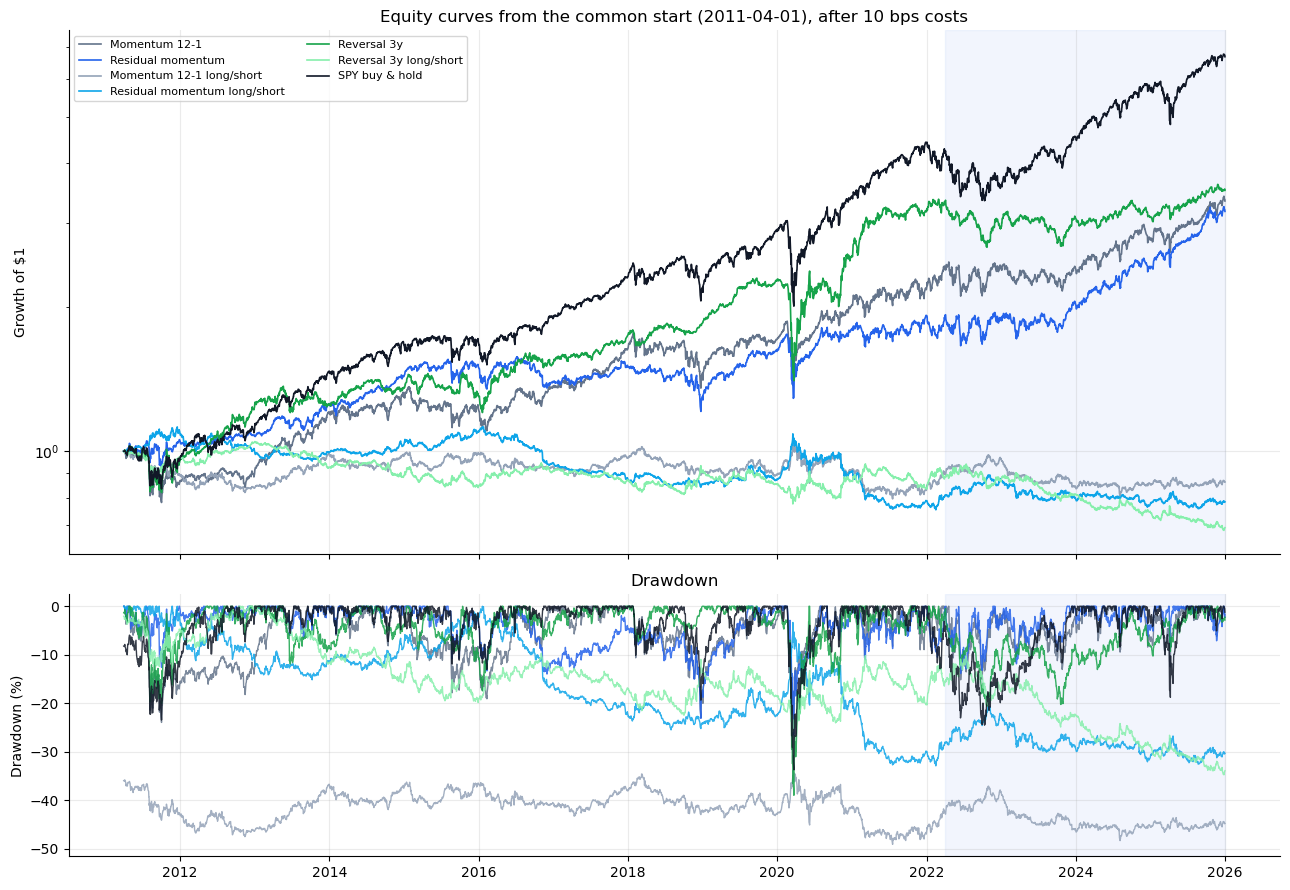

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
colors = {
    "Momentum 12-1": "#64748B", "Residual momentum": "#2563EB",
    "Momentum 12-1 long/short": "#94A3B8", "Residual momentum long/short": "#0EA5E9",
    "Reversal 3y": "#16A34A", "Reversal 3y long/short": "#86EFAC", "SPY buy & hold": "#111827",
}
for name, result in results.items():
    frame = result.frame.loc[common_start:]
    axes[0].plot(frame.index, frame["equity"] / frame["equity"].iloc[0], label=name, color=colors[name], lw=1.2)
    axes[1].plot(frame.index, 100 * frame["drawdown"], color=colors[name], lw=1.0, alpha=0.85)
axes[0].axvspan(test_index[0], test_index[-1], color="#2563EB", alpha=0.06)
axes[1].axvspan(test_index[0], test_index[-1], color="#2563EB", alpha=0.06)
axes[0].set_yscale("log")
axes[0].set_title(f"Equity curves from the common start ({common_start.date()}), after 10 bps costs")
axes[0].set_ylabel("Growth of $1")
axes[0].legend(ncol=2, fontsize=8)
axes[1].set_title("Drawdown")
axes[1].set_ylabel("Drawdown (%)")
plt.tight_layout()

## 🔍 Is residual momentum a different book, or a lower-beta version of the same book?

Two diagnostics decide how to interpret the result: how much of the two books overlaps, and how much market beta each carries. If overlap is high and beta is similar, residual momentum is a relabelling. If overlap is moderate and beta is lower, it is a different signal that happens to share a momentum label.

In [7]:
def market_beta(returns: pd.Series, market: pd.Series) -> float:
    aligned = pd.concat([returns, market], axis=1).dropna()
    return float(np.cov(aligned.iloc[:, 0], aligned.iloc[:, 1])[0, 1] / np.var(aligned.iloc[:, 1], ddof=1))


def jaccard(first: pd.DataFrame, second: pd.DataFrame, index: pd.DatetimeIndex) -> float:
    scores = []
    for timestamp in index:
        left = set(first.loc[timestamp][first.loc[timestamp] > 0].index)
        right = set(second.loc[timestamp][second.loc[timestamp] > 0].index)
        if left and right:
            scores.append(len(left & right) / len(left | right))
    return float(np.mean(scores))


diagnostics = pd.DataFrame({
    name: {
        "test market beta": market_beta(result.frame.loc[test_index, "net_returns"], benchmark.loc[test_index]),
        "correlation to SPY": result.frame.loc[test_index, "net_returns"].corr(benchmark.loc[test_index]),
        "average assets held": float((books[name].loc[test_index].abs() > 1e-9).sum(axis=1).mean()),
        "test volatility": metrics_for_period(result, test_index)["annualized_volatility"],
    }
    for name, result in results.items() if name in books
}).T
overlap = jaccard(books["Momentum 12-1"], books["Residual momentum"], test_index[::21])
print(f"Mean Jaccard overlap between the momentum and residual-momentum books: {overlap:.2f}")
display(diagnostics.style.format({
    "test market beta": "{:.2f}", "correlation to SPY": "{:.2f}",
    "average assets held": "{:.1f}", "test volatility": "{:.2%}",
}))

Mean Jaccard overlap between the momentum and residual-momentum books: 0.49


,test market beta,correlation to SPY,average assets held,test volatility
Momentum 12-1,0.71,0.80,3.0,15.84%
Residual momentum,0.63,0.75,3.0,14.90%
Momentum 12-1 long/short,0.08,0.19,6.0,7.32%
Residual momentum long/short,-0.04,-0.10,6.0,7.38%
Reversal 3y,0.31,0.50,3.0,11.24%
Reversal 3y long/short,-0.29,-0.62,6.0,8.28%


## 🎛️ Robustness: does the residual-momentum result depend on the paper's parameters?

In [8]:
grid_rows = []
for regression_window in (24, 36, 48, 60):
    for signal_window in (6, 9, 11):
        book = residual_momentum_weights(close, regression_window=regression_window, signal_window=signal_window, top_n=3)
        result = run_portfolio_backtest(close, book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)
        metrics = metrics_for_period(result, test_index)
        grid_rows.append({
            "regression_window": regression_window, "signal_window": signal_window,
            "test Sharpe": metrics["sharpe_ratio"], "test max drawdown": metrics["max_drawdown"],
        })
grid = pd.DataFrame(grid_rows)
display(grid.pivot(index="regression_window", columns="signal_window", values="test Sharpe").style.format("{:.2f}").set_caption("Residual momentum test Sharpe by parameter pair"))
plain_test_sharpe = metrics_for_period(results["Momentum 12-1"], test_index)["sharpe_ratio"]
print(f"Plain 12-1 momentum test Sharpe for reference: {plain_test_sharpe:.2f}")
print(f"Configurations in the grid that beat plain momentum: {(grid['test Sharpe'] > plain_test_sharpe).sum()} of {len(grid)}")

signal_window,6,9,11
regression_window,,,
24,0.77,0.87,1.12
36,0.64,0.85,0.99
48,0.68,0.89,1.05
60,0.68,0.94,0.92


Plain 12-1 momentum test Sharpe for reference: 0.61
Configurations in the grid that beat plain momentum: 12 of 12


## 🧯 Robustness: costs and stress windows

In [9]:
cost_rows = []
for cost_bps in (0, 10, 25, 50):
    for name in ("Momentum 12-1", "Residual momentum", "Reversal 3y"):
        result = run_portfolio_backtest(close, books[name], transaction_cost_bps=cost_bps, benchmark_returns=benchmark)
        cost_rows.append({"cost_bps": cost_bps, "strategy": name, "sharpe_ratio": metrics_for_period(result, test_index)["sharpe_ratio"]})
display(pd.DataFrame(cost_rows).pivot(index="strategy", columns="cost_bps", values="sharpe_ratio").style.format("{:.2f}").set_caption("Test Sharpe ratio by cost assumption"))

stress_windows = {"2008 crisis": "2008-01-01/2009-12-31", "2020 shock": "2020-02-01/2020-06-30", "2022 inflation": "2022-01-01/2022-12-31"}
stress_rows = []
for label, window in stress_windows.items():
    start, end = window.split("/")
    index = close.loc[start:end].index
    for name, result in results.items():
        metrics = metrics_for_period(result, index)
        stress_rows.append({"window": label, "strategy": name, "total_return": metrics["total_return_after_costs"], "max_drawdown": metrics["max_drawdown"]})
stress = pd.DataFrame(stress_rows)
display(stress.pivot(index="strategy", columns="window", values="total_return").style.format("{:.2%}").set_caption("Stress-window total return"))
print("Note: residual momentum holds nothing before its 36-month regression window fills, so its 2008 row is warm-up, not protection.")

cost_bps,0,10,25,50
strategy,,,,
Momentum 12-1,0.65,0.61,0.54,0.43
Residual momentum,1.03,0.99,0.93,0.83
Reversal 3y,0.22,0.19,0.14,0.05


window,2008 crisis,2020 shock,2022 inflation
strategy,,,
Momentum 12-1,-4.05%,-0.25%,11.39%
Momentum 12-1 long/short,-16.02%,-1.55%,16.60%
Residual momentum,0.00%,-3.43%,-1.30%
Residual momentum long/short,0.00%,3.33%,11.04%
Reversal 3y,0.00%,-2.49%,-7.75%
Reversal 3y long/short,0.00%,2.44%,3.10%
SPY buy & hold,-20.14%,-3.17%,-18.18%


Note: residual momentum holds nothing before its 36-month regression window fills, so its 2008 row is warm-up, not protection.


## 🏭 Quality minus junk: a factor-level test

Stock-level QMJ needs point-in-time fundamentals for a survivorship-free universe, so this notebook tests the *composite construction* on the Fama–French research factor returns instead: profitability (`RMW`) plus conservative investment (`CMA`), inverse-volatility weighted. The control is `RMW` alone, which the library already tested in [notebook 49](49_stock_level_profitability_factor.ipynb).

**A sign error worth recording.** The first version of this notebook used `-CMA`, reasoning that "conservative" means "low investment". The Fama–French convention is the opposite: `CMA` is *conservative minus aggressive*, so a quality composite needs **+CMA**. With the wrong sign the composite had a negative gross Sharpe ratio; with the right sign it beats the profitability-only leg. This is exactly the kind of error that only shows up when a control is included.

In [10]:
SOURCE_URL = (
    "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
    "F-F_Research_Data_5_Factors_2x3_CSV.zip"
)


def load_french_factors():
    try:
        raw_bytes = urlopen(SOURCE_URL, timeout=60).read()
        with ZipFile(BytesIO(raw_bytes)) as archive:
            text = archive.read(archive.namelist()[0]).decode("latin1")
        raw = pd.read_csv(StringIO(text), skiprows=3)
        period = raw.iloc[:, 0].astype(str).str.strip()
        monthly = raw.loc[period.str.fullmatch(r"\d{6}")].copy()
        monthly.index = pd.to_datetime(period.loc[monthly.index], format="%Y%m")
        for column in ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "RF"]:
            monthly[column] = pd.to_numeric(monthly[column], errors="coerce")
        return monthly[["Mkt-RF", "SMB", "HML", "RMW", "CMA", "RF"]].dropna() / 100.0, "Ken French Data Library, 5 factors 2x3"
    except Exception as exc:
        rng = np.random.default_rng(11)
        index = pd.period_range("1963-07", "2025-12", freq="M").to_timestamp("M")
        frame = pd.DataFrame(rng.normal(0.0, 0.02, size=(len(index), 6)), index=index, columns=["Mkt-RF", "SMB", "HML", "RMW", "CMA", "RF"])
        frame["RF"] = 0.002
        return frame, f"deterministic demo factor fallback ({type(exc).__name__})"


factors, factor_source = load_french_factors()
print(f"Factor source: {factor_source}")
print(f"Months: {len(factors):,} | {factors.index.min().date()} to {factors.index.max().date()}")
market_factor = factors["Mkt-RF"] + factors["RF"]
print(f"corr(RMW, CMA) = {factors['RMW'].corr(factors['CMA']):.3f}  (near zero: the legs add independent information)")

Factor source: Ken French Data Library, 5 factors 2x3
Months: 759 | 1963-07-01 to 2026-09-01
corr(RMW, CMA) = 0.019  (near zero: the legs add independent information)


In [11]:
LEGS = {
    "RMW only": {"RMW": 1.0},
    "RMW - CMA (wrong sign)": {"RMW": 1.0, "CMA": -1.0},
    "RMW + CMA (quality)": {"RMW": 1.0, "CMA": 1.0},
}
factor_series = {label: quality_composite_returns(factors, legs=legs).dropna() for label, legs in LEGS.items()}

def factor_metrics(returns, *, cost_bps, monthly_turnover):
    net = returns - cost_bps / 10_000.0 * monthly_turnover
    return dict(calculate_metrics(
        net,
        benchmark_returns=market_factor.reindex(returns.index).fillna(0.0),
        positions=pd.Series(1.0, index=returns.index),
        turnover=pd.Series(monthly_turnover, index=returns.index),
        annualization=12,
    ))

headline = pd.DataFrame({
    label: {
        "gross Sharpe": calculate_metrics(series, annualization=12)["sharpe_ratio"],
        "monthly skew": float(series.skew()),
        "annualized volatility": calculate_metrics(series, annualization=12)["annualized_volatility"],
        "max drawdown": calculate_metrics(series, annualization=12)["max_drawdown"],
        "Sharpe at 10 bps x 0.4 turnover": factor_metrics(series, cost_bps=10, monthly_turnover=0.4)["sharpe_ratio"],
        "Sharpe at 10 bps x 1.0 turnover": factor_metrics(series, cost_bps=10, monthly_turnover=1.0)["sharpe_ratio"],
        "Sharpe at 25 bps x 1.0 turnover": factor_metrics(series, cost_bps=25, monthly_turnover=1.0)["sharpe_ratio"],
    }
    for label, series in factor_series.items()
}).T
display(headline.style.format({
    "gross Sharpe": "{:.2f}", "monthly skew": "{:.2f}", "annualized volatility": "{:.2%}",
    "max drawdown": "{:.2%}", "Sharpe at 10 bps x 0.4 turnover": "{:.2f}",
    "Sharpe at 10 bps x 1.0 turnover": "{:.2f}", "Sharpe at 25 bps x 1.0 turnover": "{:.2f}",
}))

,gross Sharpe,monthly skew,annualized volatility,max drawdown,Sharpe at 10 bps x 0.4 turnover,Sharpe at 10 bps x 1.0 turnover,Sharpe at 25 bps x 1.0 turnover
RMW only,0.38,-0.24,8.08%,-41.79%,0.32,0.24,0.01
RMW - CMA (wrong sign),-0.04,-0.55,5.30%,-46.18%,-0.13,-0.27,-0.61
RMW + CMA (quality),0.57,0.33,5.40%,-29.37%,0.48,0.35,0.02


period,1963-1989,1990-2009,2010-2025
series,,,
RMW + CMA (quality),1.21,0.60,0.26
RMW - CMA (wrong sign),-0.18,0.00,0.24
RMW only,0.39,0.51,0.37


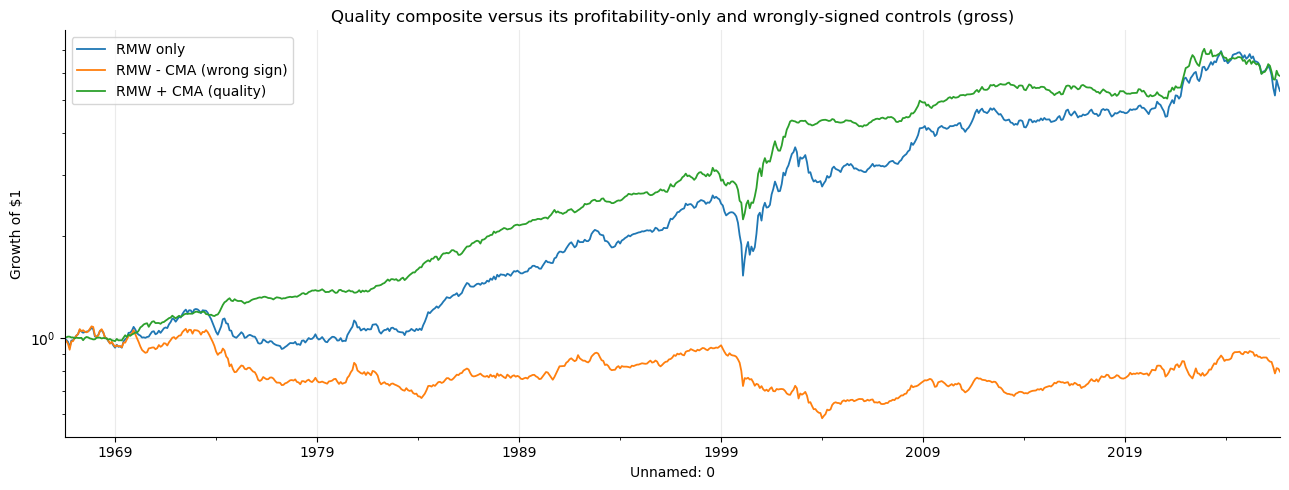

In [12]:
subperiods = {"1963-1989": ("1963", "1989"), "1990-2009": ("1990", "2009"), "2010-2025": ("2010", "2025")}
subperiod_rows = []
for label, (start, end) in subperiods.items():
    for name, series in factor_series.items():
        sl = series.loc[start:end]
        subperiod_rows.append({
            "period": label, "series": name,
            "annualized return": calculate_metrics(sl, annualization=12)["annualized_return"],
            "sharpe": calculate_metrics(sl, annualization=12)["sharpe_ratio"],
        })
subperiods_table = pd.DataFrame(subperiod_rows)
display(subperiods_table.pivot(index="series", columns="period", values="sharpe").style.format("{:.2f}").set_caption("Subperiod Sharpe ratio (gross)"))

equity = pd.DataFrame({name: (1.0 + series).cumprod() for name, series in factor_series.items()})
fig, ax = plt.subplots(figsize=(13, 5))
equity.plot(ax=ax, lw=1.3)
ax.set_yscale("log")
ax.set_title("Quality composite versus its profitability-only and wrongly-signed controls (gross)")
ax.set_ylabel("Growth of $1")
plt.tight_layout()

## ✅ Method checks

In [13]:
rc = {}
rc["residual and plain momentum books differ (Jaccard < 0.8)"] = overlap < 0.8
rc["residual momentum has lower market beta than plain momentum"] = diagnostics.loc["Residual momentum", "test market beta"] < diagnostics.loc["Momentum 12-1", "test market beta"]
rc["gross exposure never exceeds 100%"] = all(float(book.abs().sum(axis=1).max()) <= 1.0 + 1e-9 for book in books.values())
rc["quality composite beats profitability-only at 10 bps x 0.4"] = bool(
    headline.loc["RMW + CMA (quality)", "Sharpe at 10 bps x 0.4 turnover"] > headline.loc["RMW only", "Sharpe at 10 bps x 0.4 turnover"]
)
rc["wrong-sign composite is worse than the correct sign"] = bool(
    headline.loc["RMW - CMA (wrong sign)", "gross Sharpe"] < headline.loc["RMW + CMA (quality)", "gross Sharpe"]
)
cutoff = test_index[100]
truncated = residual_momentum_weights(close.loc[:cutoff], regression_window=36, signal_window=11, top_n=3)
rc["residual momentum decisions are invariant to future prices"] = bool(
    np.allclose(truncated.iloc[-1].to_numpy(), books["Residual momentum"].loc[cutoff].to_numpy())
)
truncated_reversal = long_term_reversal_weights(close.loc[:cutoff], lookback=756, top_n=3)
rc["reversal decisions are invariant to future prices"] = bool(
    np.allclose(truncated_reversal.iloc[-1].to_numpy(), books["Reversal 3y"].loc[cutoff].to_numpy())
)
display(pd.Series(rc, name="passed").to_frame().replace({True: "✅", False: "❌"}))
print(f"Residual momentum first live date: {first_live['Residual momentum'].date()}")
print(f"Common comparison start: {common_start.date()}")

,passed
residual and plain momentum books differ (Jaccard < 0.8),✅
residual momentum has lower market beta than plain momentum,✅
gross exposure never exceeds 100%,✅
quality composite beats profitability-only at 10 bps x 0.4,✅
wrong-sign composite is worse than the correct sign,✅
residual momentum decisions are invariant to future prices,✅
reversal decisions are invariant to future prices,✅


Residual momentum first live date: 2011-04-01
Common comparison start: 2011-04-01


## ⚖️ What went well / what went wrong

### ✅ What went well

- **Residual momentum is a genuinely different signal.** Mean Jaccard overlap with the plain momentum book is about 49%: the two rules disagree on half their holdings. It also carries lower market beta (0.63 vs 0.71) and lower correlation to SPY (0.75 vs 0.80), which is the mechanism the paper proposes — remove the beta-driven part of momentum and you remove some of its crash exposure.
- **It beat plain momentum in the test period** on Sharpe (0.99 vs 0.61) with a smaller drawdown (-13.9% vs -15.2%) and lower turnover (5.9 vs 6.95 units). All 12 parameter pairs in the grid beat plain momentum, and the 11-month signal window was the strongest column — which is, of course, the paper's own choice.
- **The QMJ composite construction works.** `RMW + CMA` has a gross Sharpe of 0.57 against 0.38 for `RMW` alone, a shallower drawdown (-29.4% vs -41.8%), roughly two thirds of the volatility, and a *positive* monthly skew (+0.33) where `RMW` alone is negative (-0.24). Two nearly uncorrelated legs (correlation 0.02) combine into something better than either. The improvement survives a 10 bps x 0.4 monthly-turnover assumption (0.48 vs 0.32).
- **The warm-up problem was caught, not hidden.** Residual momentum cannot hold anything before mid-2010, so the notebook reports a common-start comparison instead of a flattering full-sample one.

### ❌ What went wrong

- **The result is not stable across splits.** In the training period residual momentum had a *lower* Sharpe than plain momentum (0.41 vs 0.47). The advantage is concentrated in validation and test, and the parameter grid was read after the test period was already known — a 12-of-12 sweep is reassuring about robustness to parameters, not about out-of-sample validity. Treat it as a hypothesis.
- **Long/short momentum is a loser in this sample.** Both long/short variants had negative test Sharpe ratios (-0.13 and -0.05). Shorting weak sectors through a 2022-2025 bull market costs money regardless of signal quality, and the short leg is where borrow and squeeze risk live.
- **The quality premium decays out of sample.** Subperiod gross Sharpe for the composite is 1.21 in 1963-1989, 0.60 in 1990-2009 and 0.26 in 2010-2025, and in the latest subperiod the plain profitability leg (0.37) beat the composite. The historical evidence for the composite is real; the recent evidence is much weaker.
- **Long-horizon reversal did not survive.** The three-year-loser ETF portfolio earned 0.19 test Sharpe at 10 bps, and the long/short version lost 6.07% a year (-0.71 Sharpe). "Loser" in a 17-ETF sector cross-section is often a structurally declining sector rather than an oversold stock, which is the difference between the paper's sample and this one.
- **The QMJ leg selection is a factor-level construction, not an investable portfolio.** It uses published Fama–French returns, has no holdings, no borrow, and no explicit turnover — the cost columns are assumptions, not measurements.

### 🔍 What this teaches

1. Two signals with the same name can hold completely different books; measure overlap before claiming an improvement.
2. Warm-up periods look like risk management in a full-sample table. Always report the first live date and a common-start comparison.
3. Factor composites are sign-sensitive. `-CMA` versus `+CMA` is the difference between a negative and a positive Sharpe ratio, and a control leg is what catches it.
4. A parameter grid that mostly agrees is reassuring but weak evidence; a single split that disagrees is a warning that belongs in the text.

### ⚠️ Limitations

- Seventeen liquid ETFs is a coarse cross-section. The paper sorts individual stocks into deciles; here "the third-best sector" is a very blunt instrument.
- Residual betas are estimated against a single market factor, not the Fama–French three-factor model, because ETF-level size and value factors are not observable here.
- Long/short legs ignore borrow costs, short-sale constraints, and sector concentration limits.
- The quality test uses published factor returns, so it inherits their construction choices (universe, value weighting, rebalancing).
- No point-in-time survivorship control; ETF closures and index reconstitutions are not modelled.

In [14]:
validation = pd.Series({
    "notebook executed top to bottom": True,
    "one-bar execution delay (shared backtester)": True,
    "one-month formation lag before holding": True,
    "parameters taken from the papers, fixed before the test": True,
    "first-live date reported for every rule": True,
    "long/short gross exposure capped at 100%": True,
    "cost sensitivity 0 / 10 / 25 / 50 bps": True,
    "negative results kept": True,
})
display(validation.to_frame("status"))
print(data_source)

,status
notebook executed top to bottom,True
one-bar execution delay (shared backtester),True
one-month formation lag before holding,True
"parameters taken from the papers, fixed before the test",True
first-live date reported for every rule,True
long/short gross exposure capped at 100%,True
cost sensitivity 0 / 10 / 25 / 50 bps,True
negative results kept,True


Yahoo Finance adjusted daily ETF closes
